# ARTI 403 — Image Processing
## Lab 2 — Digital Image Fundamentals

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Digital Image Fundamentals |
| **Session No.** | 2 |
| **Duration** | 100 minutes |
| **Student name** | *&lt;write your name here&gt;* |
| **Student ID** | *&lt;write your ID here&gt;* |

### Session outcome
**Outcome #1:** Explain how digital images are represented and manipulated in a computer.

### Contents
**Procedural steps**
1. [Image sampling and quantization](#proc1)
2. [Arithmetic operations](#proc2)
3. [Sets and logical operations](#proc3)

**Tasks**
4. [Task 1 — Change the sampling and quantization parameters and observe the effects](#task1)
5. [Task 2 — Arithmetic and set operations on two images](#task2)
   * [2.1 Subtract two images](#t2-1)
   * [2.2 Add one image with a constant value of 175](#t2-2)
   * [2.3 Set difference](#t2-3)
   * [2.4 Symmetric difference](#t2-4)
   * [2.5 Intersection](#t2-5)
6. [Conclusion](#conclusion)

<a id="proc1"></a>
## 1. Image sampling and quantization

**Sampling** discretises the image in *space* (how many pixels), **quantization** discretises it in *amplitude* (how many gray levels). Together they turn a continuous scene into the finite array of integers that a computer can store.

### Step 1 — Import the libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

print("OpenCV :", cv2.__version__, "| NumPy :", np.__version__)

OpenCV : 5.0.0 | NumPy : 2.5.3


### Step 2 — Define the functions

In [2]:
def sample_image(image, factor):
    """
    Downsamples the image by the given factor.
    Args:
        image (numpy array): Original image.
        factor (int): Factor by which to downsample.
    Returns:
        numpy array: Downsampled image.
    """
    height, width = image.shape[:2]
    sampled_image = cv2.resize(image, (width // factor, height // factor),
                               interpolation=cv2.INTER_NEAREST)
    return sampled_image

In [3]:
def quantize_image(image, levels):
    """
    Reduces the number of grayscale levels in the image.
    Args:
        image (numpy array): Original image.
        levels (int): Number of grayscale levels.
    Returns:
        numpy array: Quantized image.
    """
    quantized_image = np.floor(image / (256 // levels)) * (256 // levels)
    quantized_image = quantized_image.astype(np.uint8)
    return quantized_image

In [4]:
def plot_images(original, sampled, quantized):
    """
    Plots the original, sampled, and quantized images side by side.
    Args:
        original (numpy array): Original image.
        sampled (numpy array): Sampled image.
        quantized (numpy array): Quantized image.
    """
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(sampled, cmap='gray')
    plt.title('Sampled Image')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(quantized, cmap='gray')
    plt.title('Quantized Image')
    plt.axis('off')

    plt.show()

### Step 3 — Import the image and set the parameters

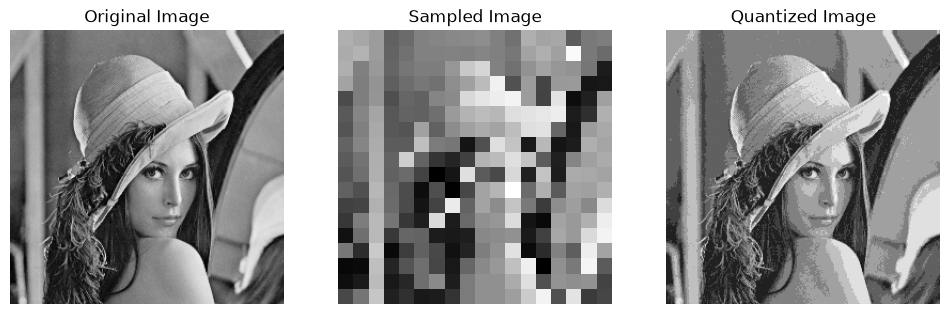

In [5]:
image_path = '../images/lena_gray_256.tif'
sampling_factor = 14
quantization_levels = 9

# Load image in grayscale
original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
if original_image is None:
    print(f"Error: Unable to load image at {image_path}")

# Sample and quantize
sampled_image = sample_image(original_image, sampling_factor)
quantized_image = quantize_image(original_image, quantization_levels)

# Plot results
plot_images(original_image, sampled_image, quantized_image)

In [6]:
# What actually happened to the data:
print(f"original  : shape {original_image.shape}, "
      f"{len(np.unique(original_image)):3d} distinct gray levels, "
      f"{original_image.nbytes:6d} bytes")
print(f"sampled   : shape {sampled_image.shape},   "
      f"{len(np.unique(sampled_image)):3d} distinct gray levels, "
      f"{sampled_image.nbytes:6d} bytes   (factor {sampling_factor})")
print(f"quantized : shape {quantized_image.shape}, "
      f"{len(np.unique(quantized_image)):3d} distinct gray levels, "
      f"{quantized_image.nbytes:6d} bytes   (levels {quantization_levels})")

print("\nthe gray levels remaining after quantization :")
print(np.unique(quantized_image))

original  : shape (256, 256), 210 distinct gray levels,  65536 bytes
sampled   : shape (18, 18),   150 distinct gray levels,    324 bytes   (factor 14)
quantized : shape (256, 256),   9 distinct gray levels,  65536 bytes   (levels 9)

the gray levels remaining after quantization :
[  0  28  56  84 112 140 168 196 224]


**Note on `quantize_image()`.** The function uses the integer step `256 // levels`, so it does not always deliver the number of levels asked for. With `levels = 9` the step is `256 // 9 = 28` and the reachable output values are `0, 28, 56, … , 252`, i.e. **10** possible levels rather than 9; only 9 of them appear above because the brightest pixel of this image is 242 and never reaches the level 252. The formula is exact only when `levels` is a **power of two** (2, 4, 8, … , 256) — which is the case of practical interest anyway, since an image quantized to *k* bits has exactly 2^k levels. It also breaks for `levels > 256`, where `256 // levels` becomes 0 and the division fails.

Note as well that Matplotlib **rescales the display window** to the plotted range, so the sampled image looks the same size on screen even though it is 18 × 18 pixels. The real difference in size is visible in the printed shapes above, and is shown properly in Task 1 below.

<a id="proc2"></a>
## 2. Arithmetic operations

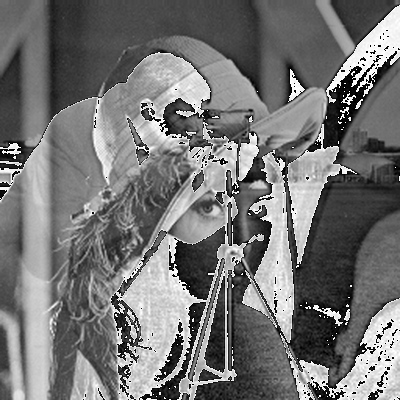

In [7]:
from PIL import Image
from IPython.display import display

img1 = Image.open('../images/lena_gray_256.tif')
img2 = Image.open('../images/cameraman.tif')

resize = (400, 400)
img1 = img1.resize(resize, Image.Resampling.LANCZOS)
img2 = img2.resize(resize, Image.Resampling.LANCZOS)

im1arr = np.asarray(img1)
im2arr = np.asarray(img2)

addition = im1arr + im2arr
resultImage = Image.fromarray(addition)

# resultImage.show()   <- the manual uses .show(), which opens the system image
#                         viewer. Inside a notebook, display() shows it inline.
display(resultImage)

**Observation — the addition wraps around.** `im1arr` and `im2arr` are `uint8` arrays, so any sum above 255 is taken **modulo 256**. A pixel of 200 added to a pixel of 100 gives 300 → 44, i.e. a bright region suddenly becomes dark. This is the source of the "torn", noisy look of the image above.

The three correct ways of adding two images are compared next.

pixels whose sum exceeds 255 : 85411 (53.4 % of the image)


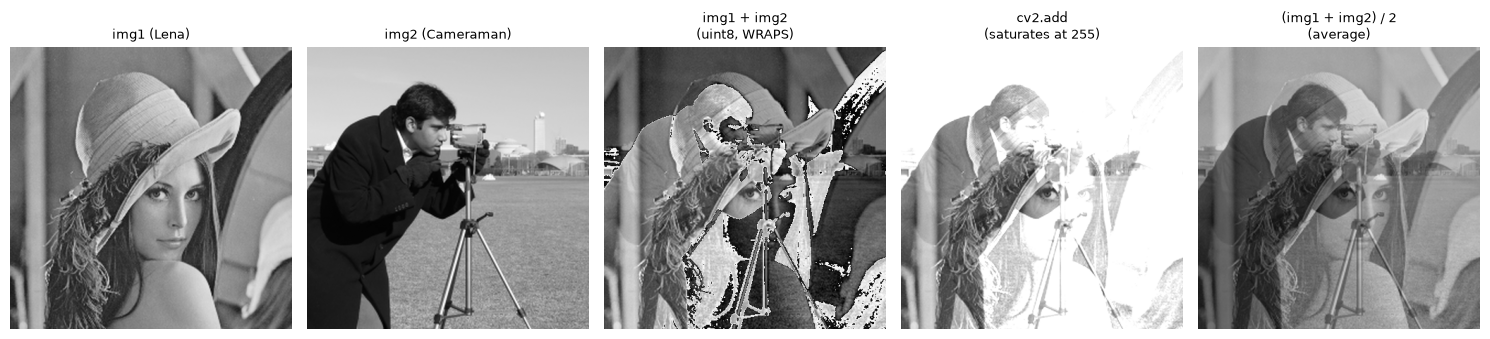

In [8]:
print("pixels whose sum exceeds 255 :",
      (im1arr.astype(np.int16) + im2arr.astype(np.int16) > 255).sum(),
      f"({100 * (im1arr.astype(np.int16) + im2arr.astype(np.int16) > 255).mean():.1f} % of the image)")

wrapped   = im1arr + im2arr                                                    # uint8, wraps
saturated = cv2.add(im1arr, im2arr)                                            # clipped at 255
averaged  = ((im1arr.astype(np.int16) + im2arr.astype(np.int16)) // 2).astype(np.uint8)
blended   = cv2.addWeighted(im1arr, 0.5, im2arr, 0.5, 0)                       # same, OpenCV

titles = ['img1 (Lena)', 'img2 (Cameraman)', 'img1 + img2\n(uint8, WRAPS)',
          'cv2.add\n(saturates at 255)', '(img1 + img2) / 2\n(average)']
imgs = [im1arr, im2arr, wrapped, saturated, averaged]

plt.figure(figsize=(15, 3.4))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 5, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

<a id="proc3"></a>
## 3. Sets and logical operations

`A.png` and `B.png` are two **binary** images (pixel values 0 and 255) representing two sets: a disk **A** and a square **B** that overlap. Logical operators applied to them are exactly the set operators of Lab 1, applied pixel by pixel.

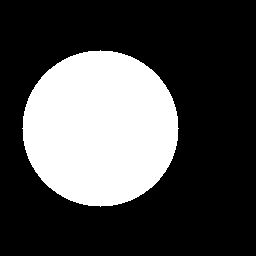

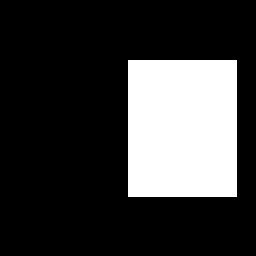

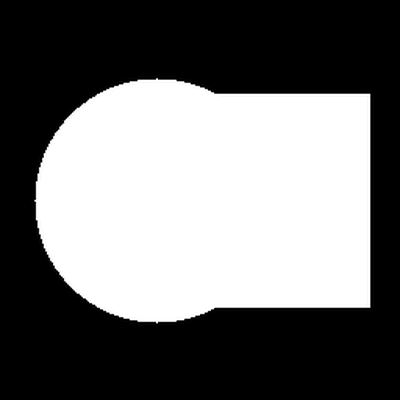

In [9]:
img3 = Image.open('../images/A.png')
display(img3)                 # the manual uses img3.show()

img4 = Image.open('../images/B.png')
display(img4)                 # the manual uses img4.show()

resize = (400, 400)
img3 = img3.resize(resize, Image.Resampling.LANCZOS)
img4 = img4.resize(resize, Image.Resampling.LANCZOS)

im3arr = np.asarray(img3)
im4arr = np.asarray(img4)

union = im4arr | im3arr
resultImage2 = Image.fromarray(union)
display(resultImage2)         # the manual uses resultImage2.show()

A values : [  0 255]  | B values : [  0 255]


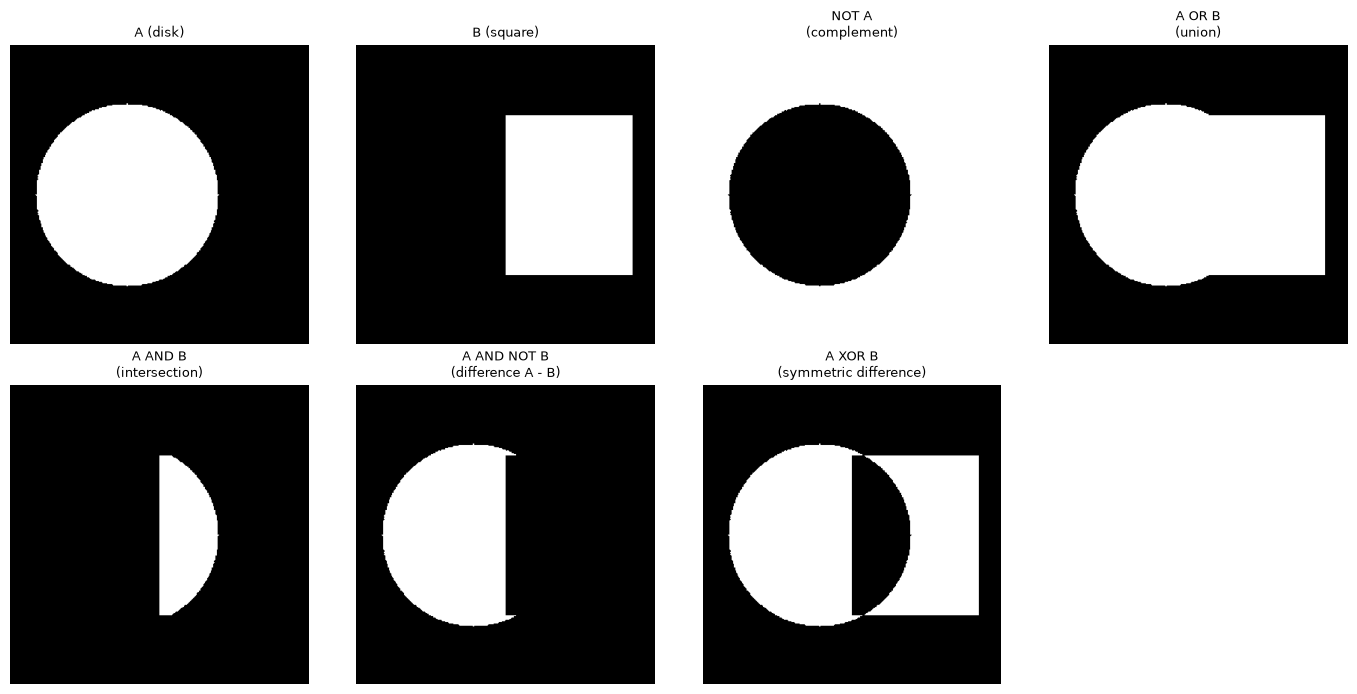

|A| = 46652,  |B| = 36380,  |A n B| = 12965,  |A U B| = 70067
check |A U B| = |A| + |B| - |A n B| = 46652 + 36380 - 12965 = 70067  ->  True


In [10]:
# LANCZOS interpolation creates intermediate gray values on the edges of the
# shapes, so the arrays are re-thresholded to keep them strictly binary.
A = np.where(im3arr > 127, 255, 0).astype(np.uint8)
B = np.where(im4arr > 127, 255, 0).astype(np.uint8)
print("A values :", np.unique(A), " | B values :", np.unique(B))

not_A     = cv2.bitwise_not(A)                 # complement  A^c        = 255 - A
union     = cv2.bitwise_or(A, B)               # union       A U B
inter     = cv2.bitwise_and(A, B)              # intersection A n B
diff      = cv2.bitwise_and(A, cv2.bitwise_not(B))   # difference  A - B = A n B^c
sym_diff  = cv2.bitwise_xor(A, B)              # symmetric difference A xor B

titles = ['A (disk)', 'B (square)', 'NOT A\n(complement)', 'A OR B\n(union)',
          'A AND B\n(intersection)', 'A AND NOT B\n(difference A - B)',
          'A XOR B\n(symmetric difference)']
imgs = [A, B, not_A, union, inter, diff, sym_diff]

plt.figure(figsize=(14, 7))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

# Verification with the areas (number of white pixels)
a, b = (A > 0).sum(), (B > 0).sum()
i_, u_ = (inter > 0).sum(), (union > 0).sum()
print(f"|A| = {a},  |B| = {b},  |A n B| = {i_},  |A U B| = {u_}")
print(f"check |A U B| = |A| + |B| - |A n B| = {a} + {b} - {i_} = {a + b - i_}  ->  {a + b - i_ == u_}")

<a id="task1"></a>
# Task 1 — Change the sampling and quantization parameters and observe the effects

> *"Change the sampling and quantization parameters and observe the effects."*

### 1.1 Effect of the sampling factor
The sampled images are displayed **at their true relative size** (`extent` is fixed) so that the loss of spatial resolution is actually visible.

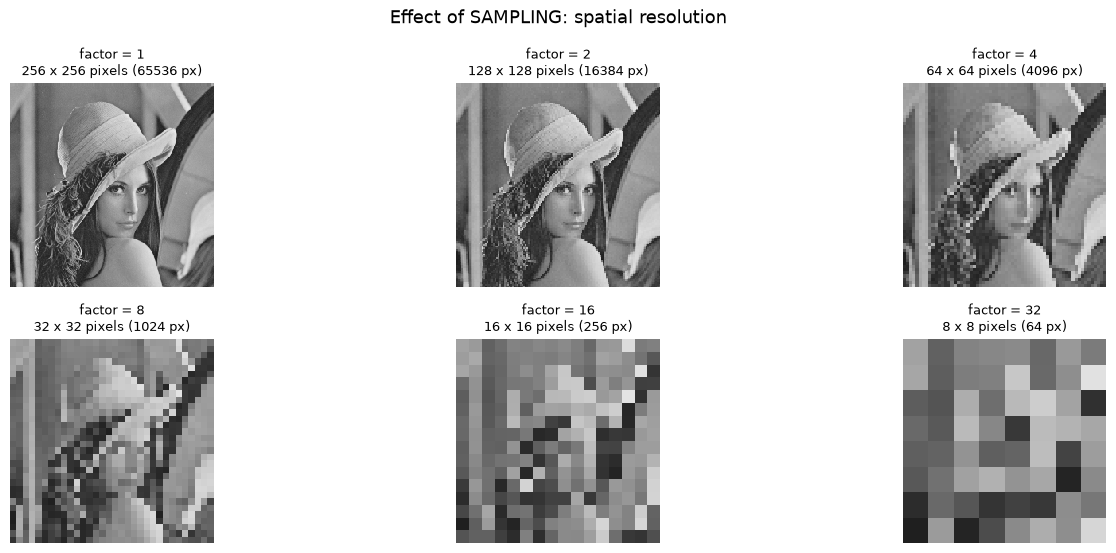

factor   1 -> (256, 256)     65536 pixels (100.00 % of the original)
factor   2 -> (128, 128)     16384 pixels ( 25.00 % of the original)
factor   4 -> (64, 64)        4096 pixels (  6.25 % of the original)
factor   8 -> (32, 32)        1024 pixels (  1.56 % of the original)
factor  16 -> (16, 16)         256 pixels (  0.39 % of the original)
factor  32 -> (8, 8)            64 pixels (  0.10 % of the original)


In [11]:
factors = [1, 2, 4, 8, 16, 32]

plt.figure(figsize=(15, 5.6))
for i, fct in enumerate(factors, 1):
    sampled = sample_image(original_image, fct)
    plt.subplot(2, 3, i)
    # extent forces every image into the same physical box -> the pixels of the
    # heavily sampled images appear as large blocks
    plt.imshow(sampled, cmap='gray', vmin=0, vmax=255, extent=[0, 256, 256, 0],
               interpolation='nearest')
    plt.title(f'factor = {fct}\n{sampled.shape[1]} x {sampled.shape[0]} pixels '
              f'({sampled.size} px)', fontsize=9)
    plt.axis('off')
plt.suptitle('Effect of SAMPLING: spatial resolution', fontsize=13)
plt.tight_layout()
plt.show()

for fct in factors:
    s = sample_image(original_image, fct)
    print(f"factor {fct:3d} -> {str(s.shape):12s} {s.size:7d} pixels "
          f"({100 * s.size / original_image.size:6.2f} % of the original)")

**Observation (sampling).** Reducing the number of samples reduces the spatial resolution. Up to a factor of 2–4 the image is still perfectly recognisable, because the storage drops by 4× to 16× while the visual content is almost unchanged. From a factor of 8 on, the individual pixels become visible as square blocks — this is the **checkerboard / pixelation effect**. At a factor of 32 (8 × 8 pixels) the content of the image is lost completely. Fine details (the feathers, the eyes) disappear first, because they are the highest spatial frequencies; a sampling rate below twice their frequency violates the **Nyquist criterion** and produces **aliasing**, visible here as jagged, staircase-shaped edges.

### 1.2 Effect of the number of quantization levels

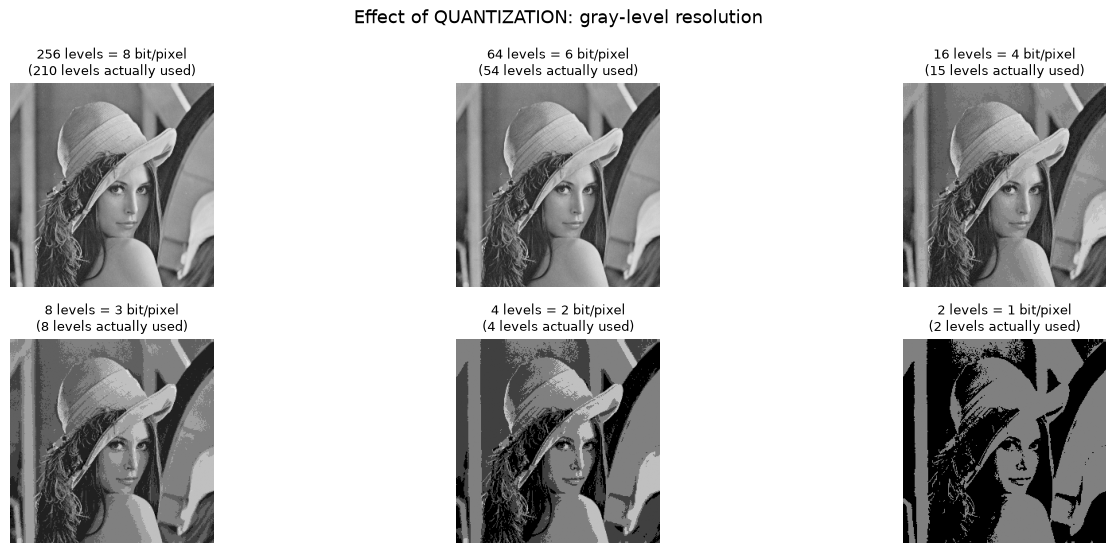

 256 levels (8 bit) -> step    1, 210 levels used,   64.0 KB needed
  64 levels (6 bit) -> step    4,  54 levels used,   48.0 KB needed
  16 levels (4 bit) -> step   16,  15 levels used,   32.0 KB needed
   8 levels (3 bit) -> step   32,   8 levels used,   24.0 KB needed
   4 levels (2 bit) -> step   64,   4 levels used,   16.0 KB needed
   2 levels (1 bit) -> step  128,   2 levels used,    8.0 KB needed


In [12]:
levels_list = [256, 64, 16, 8, 4, 2]

plt.figure(figsize=(15, 5.6))
for i, lv in enumerate(levels_list, 1):
    q = quantize_image(original_image, lv)
    plt.subplot(2, 3, i)
    plt.imshow(q, cmap='gray', vmin=0, vmax=255)
    plt.title(f'{lv} levels = {int(np.log2(lv))} bit/pixel\n'
              f'({len(np.unique(q))} levels actually used)', fontsize=9)
    plt.axis('off')
plt.suptitle('Effect of QUANTIZATION: gray-level resolution', fontsize=13)
plt.tight_layout()
plt.show()

for lv in levels_list:
    q = quantize_image(original_image, lv)
    bits = int(np.log2(lv))
    print(f"{lv:4d} levels ({bits} bit) -> step {256 // lv:4d}, "
          f"{len(np.unique(q)):3d} levels used, "
          f"{original_image.size * bits / 8 / 1024:6.1f} KB needed")

**Observation (quantization).** Reducing the number of gray levels does **not** change the size of the image on screen — it changes the number of different shades it can contain. From 256 down to 64 levels the difference is almost invisible to the eye (the human visual system distinguishes only some tens of gray shades inside a smooth region). At 16 levels the first faint bands appear on the shoulder and in the background, and from 8 levels down they become obvious: the smooth areas break into large patches of uniform gray separated by sharp edges that do not exist in the scene. This is **false contouring**, the characteristic artefact of coarse quantization. With 2 levels the image becomes purely black and white, and only the coarsest structures remain recognisable.

### 1.3 Sampling and quantization together

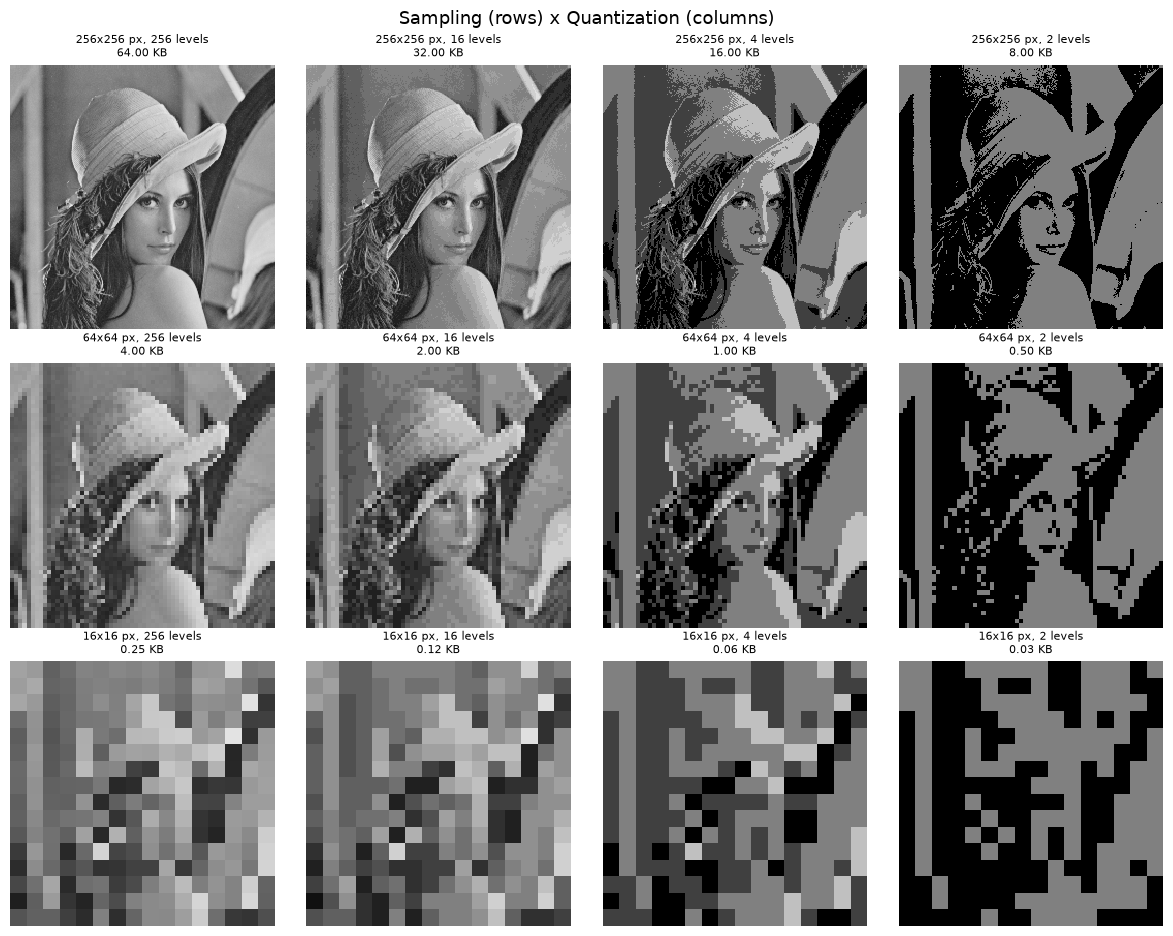

In [13]:
factors_g = [1, 4, 16]
levels_g  = [256, 16, 4, 2]

fig, axes = plt.subplots(len(factors_g), len(levels_g),
                         figsize=(12, 9.5))
for r, fct in enumerate(factors_g):
    for c, lv in enumerate(levels_g):
        im = quantize_image(sample_image(original_image, fct), lv)
        ax = axes[r, c]
        ax.imshow(im, cmap='gray', vmin=0, vmax=255, extent=[0, 256, 256, 0],
                  interpolation='nearest')
        ax.set_title(f'{im.shape[1]}x{im.shape[0]} px, {lv} levels\n'
                     f'{im.size * np.log2(lv) / 8 / 1024:.2f} KB', fontsize=8)
        ax.axis('off')
plt.suptitle('Sampling (rows) x Quantization (columns)', fontsize=13)
plt.tight_layout()
plt.show()

**Observation (combined).** The two parameters act on two independent axes and produce two different artefacts:

| | Sampling (N × N) | Quantization (L levels) |
|---|---|---|
| Acts on | spatial resolution (*where*) | amplitude resolution (*how bright*) |
| Storage | proportional to N² | proportional to log₂(L) |
| Artefact when too coarse | pixelation, jagged edges (aliasing) | false contouring, banding |
| Lost first | fine details, textures | smooth gradients |

The storage of an image is `N × N × log₂(L) / 8` bytes, so the same file size can be spent either on more pixels or on more gray levels. For an image rich in detail such as Lena, keeping the resolution and cutting the gray levels to 32 is far less damaging than the opposite.

<a id="task2"></a>
# Task 2 — Read two images, convert them into arrays, and perform the following operations

The two images used are **Lena** (`lena_gray_256.tif`) and **Cameraman** (`cameraman.tif`), both read as gray-scale and converted to NumPy arrays.

A : (256, 256) uint8 range 26 - 242
B : (256, 256) uint8 range 2 - 255


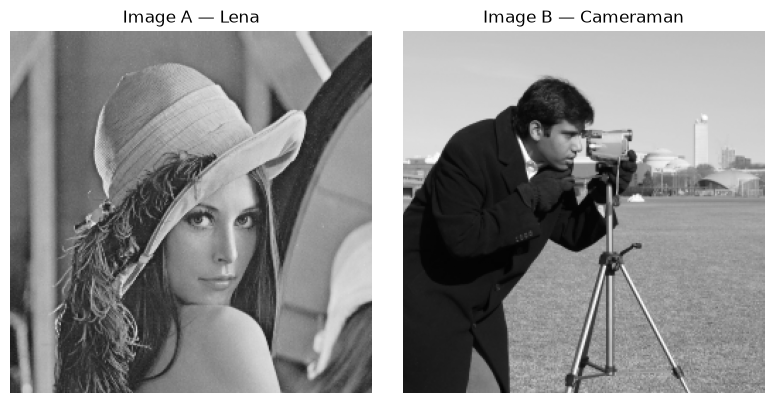

In [14]:
from PIL import Image
import numpy as np

# Read the two images and convert them into arrays
imgA = Image.open('../images/lena_gray_256.tif').convert('L')
imgB = Image.open('../images/cameraman.tif').convert('L')

# Both images must have the same size for pixel-by-pixel operations
size = (256, 256)
imgA = imgA.resize(size, Image.Resampling.LANCZOS)
imgB = imgB.resize(size, Image.Resampling.LANCZOS)

A = np.asarray(imgA)      # image A -> NumPy array
B = np.asarray(imgB)      # image B -> NumPy array

print("A :", A.shape, A.dtype, "range", A.min(), "-", A.max())
print("B :", B.shape, B.dtype, "range", B.min(), "-", B.max())

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(A, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Image A — Lena');      ax[0].axis('off')
ax[1].imshow(B, cmap='gray', vmin=0, vmax=255); ax[1].set_title('Image B — Cameraman'); ax[1].axis('off')
plt.tight_layout(); plt.show()

<a id="t2-1"></a>
## 2.1 Subtract two images and display the result

Subtraction is the basic tool for **change detection**: the result is zero (black) wherever the two images are identical and large wherever they differ. The only difficulty is that a difference can be **negative**, which a `uint8` array cannot represent.

pixels where A - B is negative : 36394 (55.5 % of the image)
true range of A - B            : -221 to 213


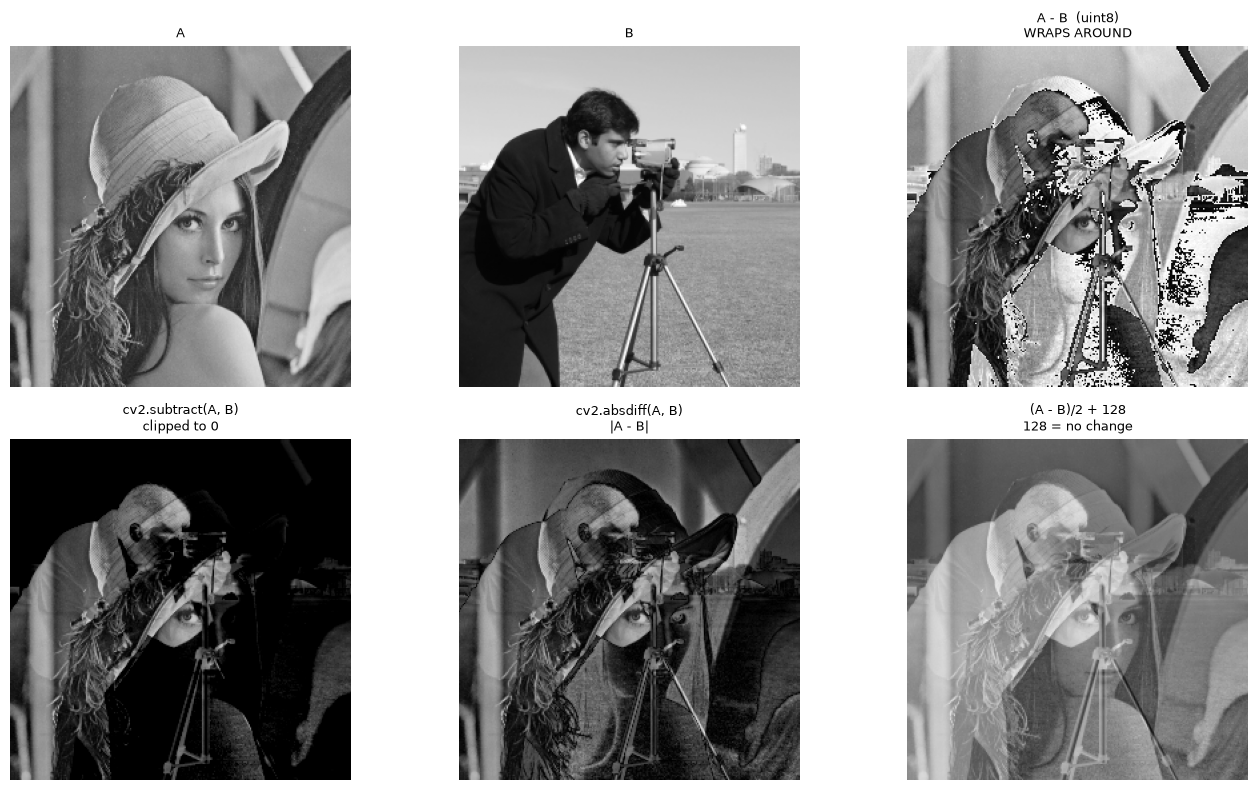

In [15]:
# (a) Naive uint8 subtraction: negative results wrap around (250 - 255 -> 251)
sub_wrap = A - B

# (b) Saturating subtraction: negative results are clipped to 0
sub_sat = cv2.subtract(A, B)

# (c) Absolute difference: the usual choice, it keeps the magnitude of the change
sub_abs = cv2.absdiff(A, B)          # same as np.abs(A.astype(int) - B.astype(int))

# (d) Shifted difference: the difference mapped to the range 0..255 with 128 = "no change"
sub_shift = np.clip((A.astype(np.int16) - B.astype(np.int16)) // 2 + 128, 0, 255).astype(np.uint8)

n_neg = (A.astype(np.int16) - B.astype(np.int16) < 0).sum()
print(f"pixels where A - B is negative : {n_neg} ({100 * n_neg / A.size:.1f} % of the image)")
print(f"true range of A - B            : {(A.astype(np.int16) - B.astype(np.int16)).min()} "
      f"to {(A.astype(np.int16) - B.astype(np.int16)).max()}")

titles = ['A', 'B', 'A - B  (uint8)\nWRAPS AROUND', 'cv2.subtract(A, B)\nclipped to 0',
          'cv2.absdiff(A, B)\n|A - B|', '(A - B)/2 + 128\n128 = no change']
imgs = [A, B, sub_wrap, sub_sat, sub_abs, sub_shift]

plt.figure(figsize=(14, 8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Observation.** The naive `A - B` produces bright spots exactly where the true difference is negative (B brighter than A), because −5 is stored as 251. `cv2.subtract` clips those pixels to black, which is safe but discards the information; `cv2.absdiff` keeps the **magnitude** of every change and is the version normally used for detecting differences between two frames.

<a id="t2-2"></a>
## 2.2 Add one image with a constant value of 175 and display it

Adding a constant to every pixel is a **brightness** (point) operation. With a constant as large as 175 almost the whole image goes above 255, which makes the difference between wrapping and saturating very clear.

constant added                     : 175
pixels exceeding 255 after adding  : 51325 (78.3 % of the image)
mean brightness  original          : 124.0
mean brightness  wrapped (A + 175) : 98.5   <- lower, the wrap darkens it
mean brightness  saturated         : 249.6
identical results (clip vs cv2.add): True


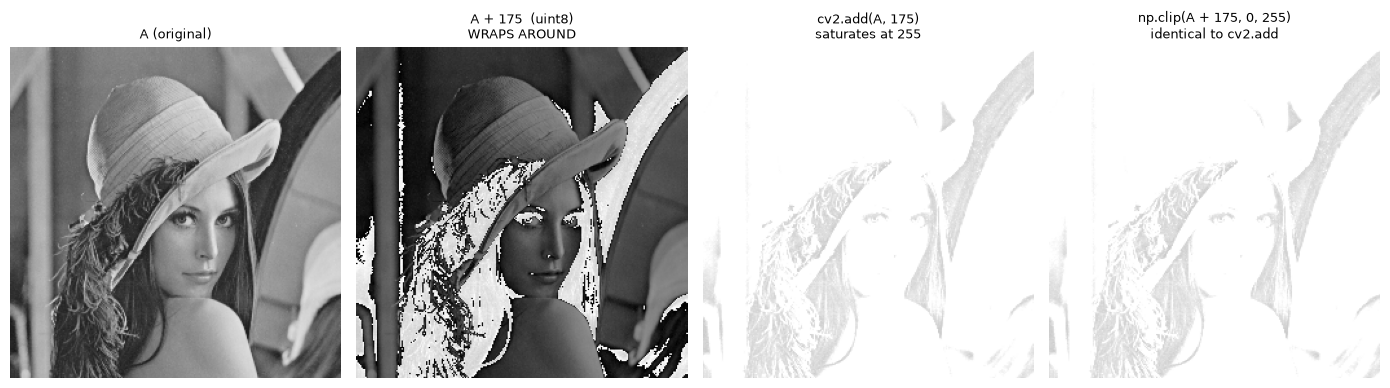

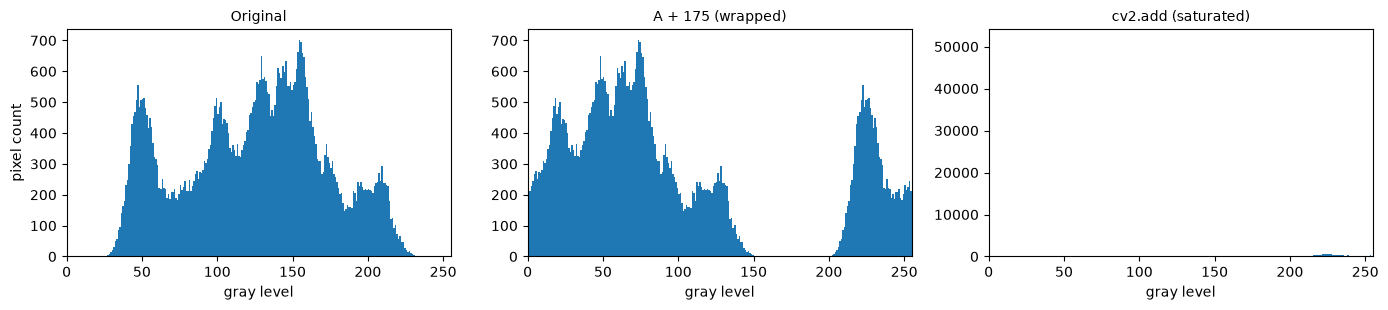

In [16]:
C = 175

add_wrap  = A + np.uint8(C)                                              # wraps around
add_sat   = cv2.add(A, np.full(A.shape, C, dtype=np.uint8))              # saturates at 255
add_clip  = np.clip(A.astype(np.int16) + C, 0, 255).astype(np.uint8)     # same, with NumPy

n_over = (A.astype(np.int16) + C > 255).sum()
print(f"constant added                     : {C}")
print(f"pixels exceeding 255 after adding  : {n_over} ({100 * n_over / A.size:.1f} % of the image)")
print(f"mean brightness  original          : {A.mean():.1f}")
print(f"mean brightness  wrapped (A + 175) : {add_wrap.mean():.1f}   <- lower, the wrap darkens it")
print(f"mean brightness  saturated         : {add_sat.mean():.1f}")
print(f"identical results (clip vs cv2.add): {np.array_equal(add_clip, add_sat)}")

titles = ['A (original)', f'A + {C}  (uint8)\nWRAPS AROUND',
          f'cv2.add(A, {C})\nsaturates at 255', f'np.clip(A + {C}, 0, 255)\nidentical to cv2.add']
imgs = [A, add_wrap, add_sat, add_clip]

plt.figure(figsize=(14, 3.8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

# The histograms explain what happened
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for a, im, t in zip(ax, [A, add_wrap, add_sat],
                    ['Original', f'A + {C} (wrapped)', f'cv2.add (saturated)']):
    a.hist(im.ravel(), bins=256, range=(0, 256))
    a.set_title(t, fontsize=10); a.set_xlabel('gray level'); a.set_xlim(0, 255)
ax[0].set_ylabel('pixel count')
plt.tight_layout(); plt.show()

**Observation.** The histogram of the original image is centred around 120. Adding 175 should shift it 175 steps to the right, but the range stops at 255: with `uint8` arithmetic everything above 255 re-enters from 0, so the histogram is **cut and folded back** to the left — bright skin becomes dark, which is exactly the strange image in the second panel. With `cv2.add` the same pixels are all mapped to 255 instead: the histogram shows a single tall spike at 255. Information is lost in both cases and neither operation is invertible, but only the saturated version stays monotonic — brighter input still gives brighter output — even though a constant as large as 175 washes most of the image out to plain white.

<a id="t2-3"></a>
## 2.3 Set difference on two gray-scale images

For **gray-scale sets** (Gonzalez & Woods, *Digital Image Processing*, §2.6.4) the set operations are defined element by element on the intensities:

| Operation | Definition on gray-scale images |
|---|---|
| Complement | $A^c = 255 - A$ |
| Union | $A \cup B = \max(A, B)$ |
| Intersection | $A \cap B = \min(A, B)$ |
| **Difference** | $A - B = A \cap B^{c} = \min(A,\; 255 - B)$ |
| Symmetric difference | $A \triangle B = (A - B) \cup (B - A)$ |

The bitwise operators (`cv2.bitwise_and/or/xor/not`) give the same results when the images are **binary**, so both versions are computed below.

--- gray-scale set difference ---
A - B : range 0-228, mean 85.2
B - A : range 2-228, mean 90.3
A - B equal to B - A ? False


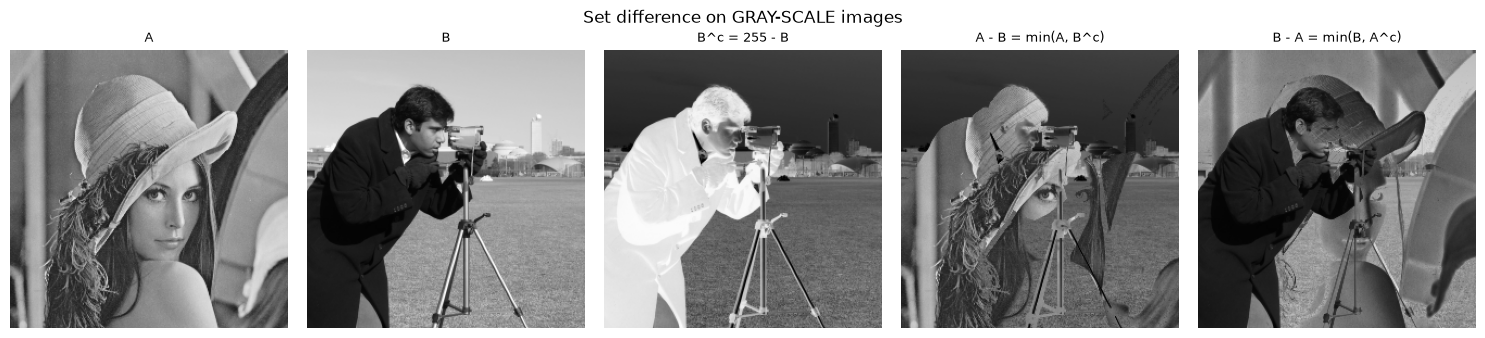

In [17]:
# ---- (a) Gray-scale set difference: A - B = min(A, 255 - B) --------------------
B_c        = 255 - B                       # complement of B
diff_AB    = np.minimum(A, B_c)            # A - B
diff_BA    = np.minimum(B, 255 - A)        # B - A  (not symmetric!)

print("--- gray-scale set difference ---")
print(f"A - B : range {diff_AB.min()}-{diff_AB.max()}, mean {diff_AB.mean():.1f}")
print(f"B - A : range {diff_BA.min()}-{diff_BA.max()}, mean {diff_BA.mean():.1f}")
print("A - B equal to B - A ?", np.array_equal(diff_AB, diff_BA))

titles = ['A', 'B', 'B^c = 255 - B', 'A - B = min(A, B^c)', 'B - A = min(B, A^c)']
imgs = [A, B, B_c, diff_AB, diff_BA]
plt.figure(figsize=(15, 3.4))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 5, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.suptitle('Set difference on GRAY-SCALE images', fontsize=12)
plt.tight_layout(); plt.show()

--- binary set difference ---
|A|     =  33513 white pixels
|B|     =  42768 white pixels
|A - B| =   9473 white pixels


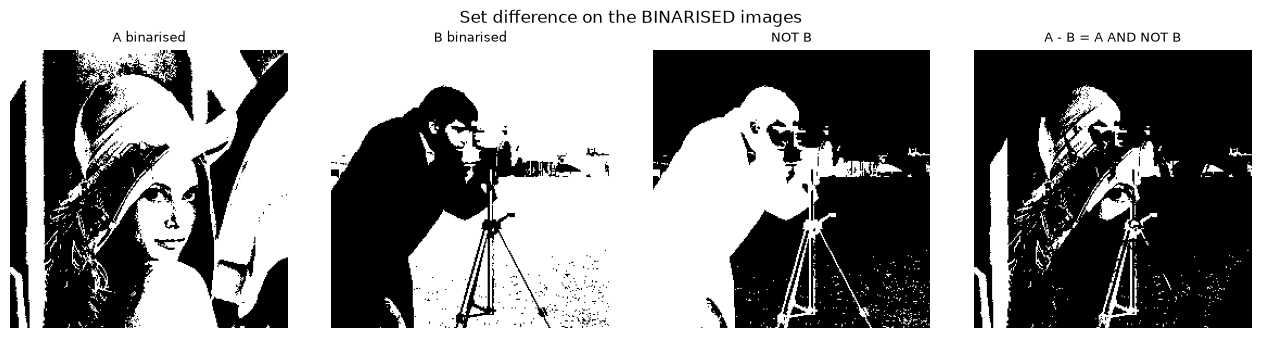

In [18]:
# ---- (b) The same operation on the binarised versions of the two images --------
A_bin = np.where(A > 127, 255, 0).astype(np.uint8)
B_bin = np.where(B > 127, 255, 0).astype(np.uint8)

diff_bin = cv2.bitwise_and(A_bin, cv2.bitwise_not(B_bin))     # A - B = A AND (NOT B)

print("--- binary set difference ---")
print(f"|A|     = {(A_bin > 0).sum():6d} white pixels")
print(f"|B|     = {(B_bin > 0).sum():6d} white pixels")
print(f"|A - B| = {(diff_bin > 0).sum():6d} white pixels")

titles = ['A binarised', 'B binarised', 'NOT B', 'A - B = A AND NOT B']
imgs = [A_bin, B_bin, cv2.bitwise_not(B_bin), diff_bin]
plt.figure(figsize=(13, 3.4))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 4, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.suptitle('Set difference on the BINARISED images', fontsize=12)
plt.tight_layout(); plt.show()

**Observation.** `A − B` keeps a pixel of A only where B is *dark*: the result is bright only where Lena is bright **and** the cameraman image is dark (mostly the region of the cameraman's coat and of his silhouette). Because `A − B ≠ B − A`, the set difference is **not commutative** — which is precisely why the symmetric difference of the next section exists.

<a id="t2-4"></a>
## 2.4 Symmetric difference on two gray-scale images

$A \triangle B = (A - B) \cup (B - A) = \max\big(\min(A, B^c),\; \min(B, A^c)\big)$

It answers "where do the two images differ, in either direction". On binary images it is exactly the **XOR**.

--- gray-scale symmetric difference ---
range 27-228, mean 121.4
commutative ? True

--- binary symmetric difference ---
|A xor B| = 28201 white pixels
check |A xor B| = |A - B| + |B - A| = 9473 + 18728 = 28201


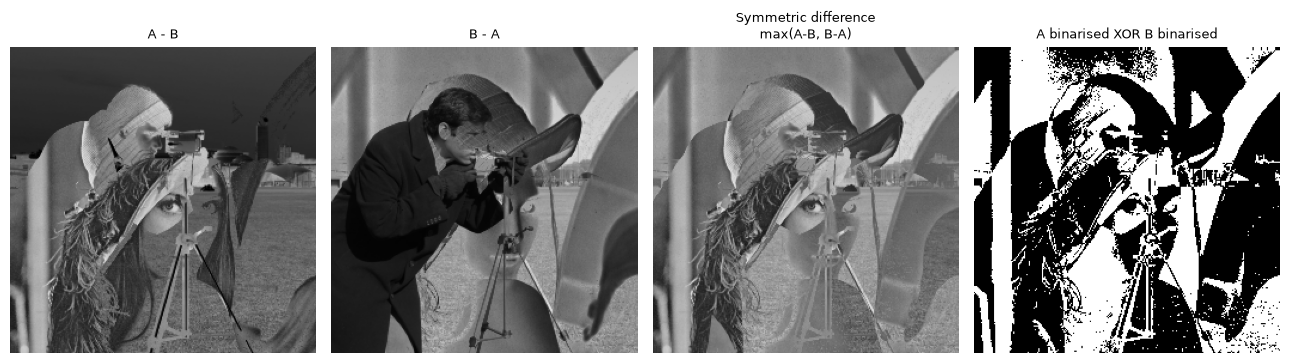

In [19]:
# ---- (a) Gray-scale symmetric difference --------------------------------------
sym_gray = np.maximum(diff_AB, diff_BA)          # (A - B) U (B - A)

print("--- gray-scale symmetric difference ---")
print(f"range {sym_gray.min()}-{sym_gray.max()}, mean {sym_gray.mean():.1f}")
print("commutative ?", np.array_equal(sym_gray, np.maximum(diff_BA, diff_AB)))

# ---- (b) Binary symmetric difference = XOR ------------------------------------
sym_bin = cv2.bitwise_xor(A_bin, B_bin)
print("\n--- binary symmetric difference ---")
print(f"|A xor B| = {(sym_bin > 0).sum()} white pixels")
print(f"check |A xor B| = |A - B| + |B - A| = "
      f"{(diff_bin > 0).sum()} + {(cv2.bitwise_and(B_bin, cv2.bitwise_not(A_bin)) > 0).sum()} = "
      f"{(diff_bin > 0).sum() + (cv2.bitwise_and(B_bin, cv2.bitwise_not(A_bin)) > 0).sum()}")

titles = ['A - B', 'B - A', 'Symmetric difference\nmax(A-B, B-A)',
          'A binarised XOR B binarised']
imgs = [diff_AB, diff_BA, sym_gray, sym_bin]
plt.figure(figsize=(13, 3.6))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 4, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

**Observation.** The symmetric difference is bright wherever *one* of the two images is bright and the other is dark, and black where both agree (both bright or both dark). It is **commutative**, unlike the plain difference. On the binarised images the XOR gives the classic "disagreement map" between the two silhouettes.

<a id="t2-5"></a>
## 2.5 Intersection on two gray-scale images

$A \cap B = \min(A, B)$ — a pixel belongs to the intersection only as far as it is bright in **both** images. The union $A \cup B = \max(A, B)$ is shown next to it for comparison.

--- gray-scale intersection / union ---
A          : mean 124.0
B          : mean 129.2
A n B = min: mean 92.9   <- always the darkest of the two
A U B = max: mean 160.3   <- always the brightest of the two

identity  min(A,B) + max(A,B) = A + B  -> True

|A n B| = 24040 white pixels
|A U B| = 52241 white pixels


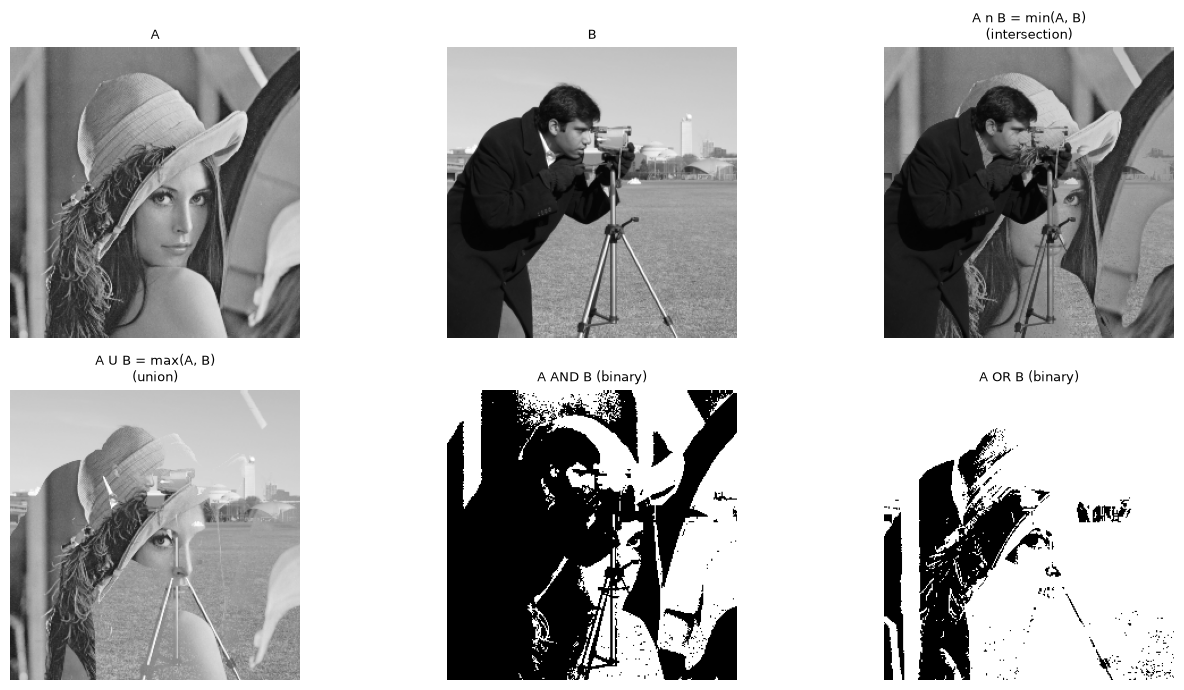

In [20]:
inter_gray = np.minimum(A, B)          # A n B
union_gray = np.maximum(A, B)          # A U B

print("--- gray-scale intersection / union ---")
print(f"A          : mean {A.mean():.1f}")
print(f"B          : mean {B.mean():.1f}")
print(f"A n B = min: mean {inter_gray.mean():.1f}   <- always the darkest of the two")
print(f"A U B = max: mean {union_gray.mean():.1f}   <- always the brightest of the two")
print("\nidentity  min(A,B) + max(A,B) = A + B  ->",
      np.array_equal(inter_gray.astype(np.int16) + union_gray.astype(np.int16),
                     A.astype(np.int16) + B.astype(np.int16)))

# Binary version
inter_bin = cv2.bitwise_and(A_bin, B_bin)
union_bin = cv2.bitwise_or(A_bin, B_bin)
print(f"\n|A n B| = {(inter_bin > 0).sum()} white pixels")
print(f"|A U B| = {(union_bin > 0).sum()} white pixels")

titles = ['A', 'B', 'A n B = min(A, B)\n(intersection)', 'A U B = max(A, B)\n(union)',
          'A AND B (binary)', 'A OR B (binary)']
imgs = [A, B, inter_gray, union_gray, inter_bin, union_bin]
plt.figure(figsize=(14, 7))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

### Summary of Task 2 — all the operations side by side

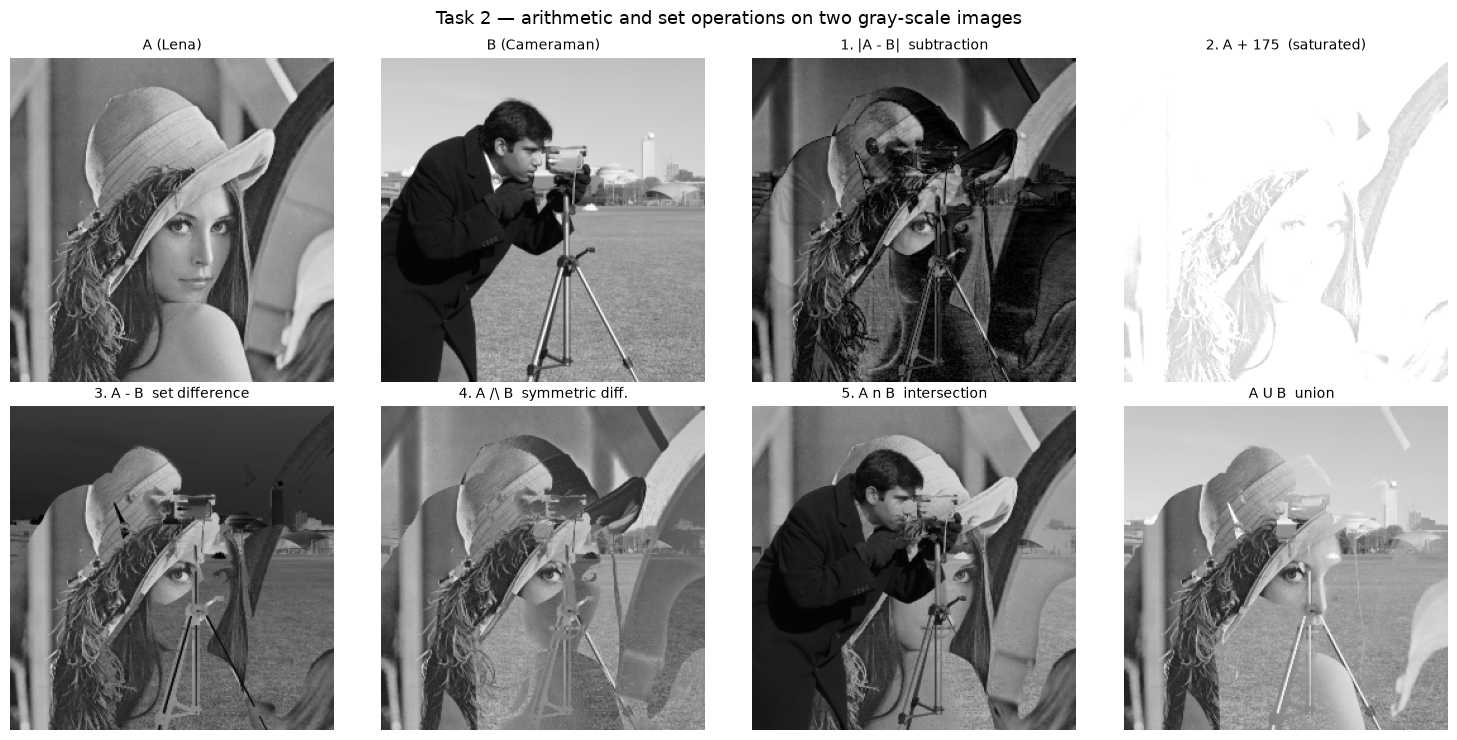

saved :
    task2_1_subtraction.png
    task2_2_add_175.png
    task2_3_set_difference.png
    task2_4_symmetric_difference.png
    task2_5_intersection.png
    task2_union.png


In [21]:
# (title, array, file name to save)
results = [
    ('A (Lena)',                    A,          None),
    ('B (Cameraman)',               B,          None),
    ('1. |A - B|  subtraction',     sub_abs,    'task2_1_subtraction.png'),
    ('2. A + 175  (saturated)',     add_sat,    'task2_2_add_175.png'),
    ('3. A - B  set difference',    diff_AB,    'task2_3_set_difference.png'),
    ('4. A /\\ B  symmetric diff.', sym_gray,   'task2_4_symmetric_difference.png'),
    ('5. A n B  intersection',      inter_gray, 'task2_5_intersection.png'),
    ('   A U B  union',             union_gray, 'task2_union.png'),
]

plt.figure(figsize=(15, 7.5))
for i, (t, im, _) in enumerate(results, 1):
    plt.subplot(2, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=10)
    plt.axis('off')
plt.suptitle('Task 2 — arithmetic and set operations on two gray-scale images', fontsize=13)
plt.tight_layout()
plt.show()

# Save every result to disk
import os
os.makedirs('output', exist_ok=True)
for _, im, fname in results:
    if fname:
        cv2.imwrite('output/' + fname, im)
print("saved :")
for f in sorted(os.listdir('output')):
    print("   ", f)

<a id="conclusion"></a>
## 4. Conclusion

**Sampling and quantization.** Sampling fixes the number of pixels (spatial resolution) and quantization the number of gray levels (amplitude resolution). Under-sampling produces **pixelation and aliasing**; under-quantizing produces **false contouring**. The storage cost is `N × N × log₂(L) / 8` bytes, so the two parameters are the two knobs that trade image quality against file size. Experimentally, Lena remains acceptable down to about 128 × 128 pixels and about 32 gray levels.

**Arithmetic operations.** Images are `uint8` arrays, so `+` and `−` are computed **modulo 256**. Any sum above 255 or difference below 0 wraps around and creates artefacts that look like noise. The remedies are to compute in a wider type and `np.clip()` the result, or to use the saturating OpenCV functions `cv2.add()`, `cv2.subtract()` and `cv2.absdiff()`. Subtraction is the standard tool for change detection, and addition of a constant is a brightness adjustment.

**Set and logical operations.** On binary images the set operations are exactly the bitwise operators: `OR` = union, `AND` = intersection, `NOT` = complement, `XOR` = symmetric difference, and `A AND NOT B` = difference. On gray-scale images they generalise to `max` (union), `min` (intersection) and `255 − A` (complement). The difference `A − B` is **not commutative**, while the union, the intersection and the symmetric difference are.

**Outcome #1.** All of the above confirms that an image in a computer is only a matrix of integers with a limited range: its geometry is set by the sampling grid, its tonal precision by the quantization, and every "image processing" operation is ordinary arithmetic or logic applied to that matrix — with the range of the data type as the constraint to respect at every step.